In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt  
import seaborn as sns

train = pd.read_csv("../data/fraudTrain.csv")
test  = pd.read_csv("../data/fraudTest.csv")
df = pd.concat([train, test], ignore_index=True)
df = df.drop(columns=["Unnamed: 0"])
del train, test

In [ ]:
print(df.shape)    

(1852394, 22)


In [ ]:
print(df.size)      


40752668


In [ ]:
print(df.head())   

  trans_date_trans_time            cc_num                            merchant  \
0   2019-01-01 00:00:18  2703186189652095          fraud_Rippin, Kub and Mann   
1   2019-01-01 00:00:44      630423337322     fraud_Heller, Gutmann and Zieme   
2   2019-01-01 00:00:51    38859492057661                fraud_Lind-Buckridge   
3   2019-01-01 00:01:16  3534093764340240  fraud_Kutch, Hermiston and Farrell   
4   2019-01-01 00:03:06   375534208663984                 fraud_Keeling-Crist   

        category     amt      first     last gender  \
0       misc_net    4.97   Jennifer    Banks      F   
1    grocery_pos  107.23  Stephanie     Gill      F   
2  entertainment  220.11     Edward  Sanchez      M   
3  gas_transport   45.00     Jeremy    White      M   
4       misc_pos   41.96      Tyler   Garcia      M   

                         street            city  ...      lat      long  \
0                561 Perry Cove  Moravian Falls  ...  36.0788  -81.1781   
1  43039 Riley Greens Suite 393 

In [ ]:
print(df.tail())    

        trans_date_trans_time            cc_num               merchant  \
1852389   2020-12-31 23:59:07    30560609640617  fraud_Reilly and Sons   
1852390   2020-12-31 23:59:09  3556613125071656   fraud_Hoppe-Parisian   
1852391   2020-12-31 23:59:15  6011724471098086        fraud_Rau-Robel   
1852392   2020-12-31 23:59:24     4079773899158  fraud_Breitenberg LLC   
1852393   2020-12-31 23:59:34  4170689372027579      fraud_Dare-Marvin   

               category     amt    first     last gender  \
1852389  health_fitness   43.77  Michael    Olson      M   
1852390       kids_pets  111.84     Jose  Vasquez      M   
1852391       kids_pets   86.88      Ann   Lawson      F   
1852392          travel    7.99     Eric  Preston      M   
1852393   entertainment   38.13   Samuel     Frey      M   

                             street          city  ...      lat      long  \
1852389         558 Michael Estates         Luray  ...  40.4931  -91.8912   
1852390         572 Davis Mountains  Lak

In [ ]:
print(df.info())   

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1852394 entries, 0 to 1852393
Data columns (total 22 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   trans_date_trans_time  object 
 1   cc_num                 int64  
 2   merchant               object 
 3   category               object 
 4   amt                    float64
 5   first                  object 
 6   last                   object 
 7   gender                 object 
 8   street                 object 
 9   city                   object 
 10  state                  object 
 11  zip                    int64  
 12  lat                    float64
 13  long                   float64
 14  city_pop               int64  
 15  job                    object 
 16  dob                    object 
 17  trans_num              object 
 18  unix_time              int64  
 19  merch_lat              float64
 20  merch_long             float64
 21  is_fraud               int64  
dtypes: float64(5), int

In [ ]:
print(df.describe())

             cc_num           amt           zip           lat          long  \
count  1.852394e+06  1.852394e+06  1.852394e+06  1.852394e+06  1.852394e+06   
mean   4.173860e+17  7.006357e+01  4.881326e+04  3.853931e+01 -9.022783e+01   
std    1.309115e+18  1.592540e+02  2.688185e+04  5.071470e+00  1.374789e+01   
min    6.041621e+10  1.000000e+00  1.257000e+03  2.002710e+01 -1.656723e+02   
25%    1.800429e+14  9.640000e+00  2.623700e+04  3.466890e+01 -9.679800e+01   
50%    3.521417e+15  4.745000e+01  4.817400e+04  3.935430e+01 -8.747690e+01   
75%    4.642255e+15  8.310000e+01  7.204200e+04  4.194040e+01 -8.015800e+01   
max    4.992346e+18  2.894890e+04  9.992100e+04  6.669330e+01 -6.795030e+01   

           city_pop     unix_time     merch_lat    merch_long      is_fraud  
count  1.852394e+06  1.852394e+06  1.852394e+06  1.852394e+06  1.852394e+06  
mean   8.864367e+04  1.358674e+09  3.853898e+01 -9.022794e+01  5.210015e-03  
std    3.014876e+05  1.819508e+07  5.105604e+00  1.375

In [ ]:
print(df.describe(include='object'))

       trans_date_trans_time           merchant       category        first  \
count                1852394            1852394        1852394      1852394   
unique               1819551                693             14          355   
top      2019-04-22 16:02:01  fraud_Kilback LLC  gas_transport  Christopher   
freq                       4               6262         188029        38112   

           last   gender            street        city    state  \
count   1852394  1852394           1852394     1852394  1852394   
unique      486        2               999         906       51   
top       Smith        F  908 Brooks Brook  Birmingham       TX   
freq      40940  1014749              4392        8040   135269   

                      job         dob                         trans_num  
count             1852394     1852394                           1852394  
unique                497         984                           1852394  
top     Film/video editor  1977-03-23  1765bb4

In [ ]:
print(df['is_fraud'].value_counts())
print(df['is_fraud'].value_counts(normalize=True) * 100)

is_fraud
0    1842743
1       9651
Name: count, dtype: int64
is_fraud
0    99.478999
1     0.521001
Name: proportion, dtype: float64


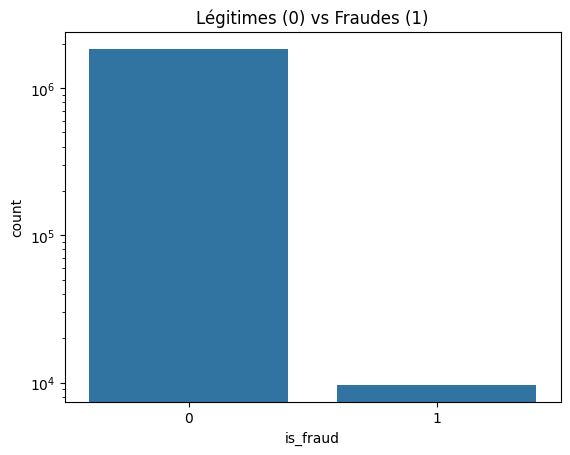

In [ ]:
sns.countplot(x='is_fraud', data=df)
plt.yscale('log')
plt.title("Légitimes (0) vs Fraudes (1)")
plt.show()
